In [1]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

In [2]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [4]:
indice = 0
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]
print(f"Dimensões do palete: {palete_comprimento}x{palete_largura}")
print(f"Dimensões da caixa: {caixa_comprimento}x{caixa_largura}")

Dimensões do palete: 8x6
Dimensões da caixa: 3x2


In [5]:
dimensoes_palete = [palete_comprimento, palete_largura]
L, W = sorted(dimensoes_palete, reverse=True)
print(f"Dimensões classificadas do palete: {L}x{W}")

Dimensões classificadas do palete: 8x6


In [8]:
dimensoes_caixa = [caixa_comprimento, caixa_largura]
l_um, w_um = sorted(dimensoes_caixa, reverse=True)
print(f"Dimensões classificadas da caixa deitada: {l_um}x{w_um}")

Dimensões classificadas da caixa deitada: 3x2


In [7]:
l_dois, w_dois = dimensoes_caixa[::-1]
print(f"Dimensões classificadas da caixa em pé: {l_dois}x{w_dois}")

Dimensões classificadas da caixa em pé: 2x3


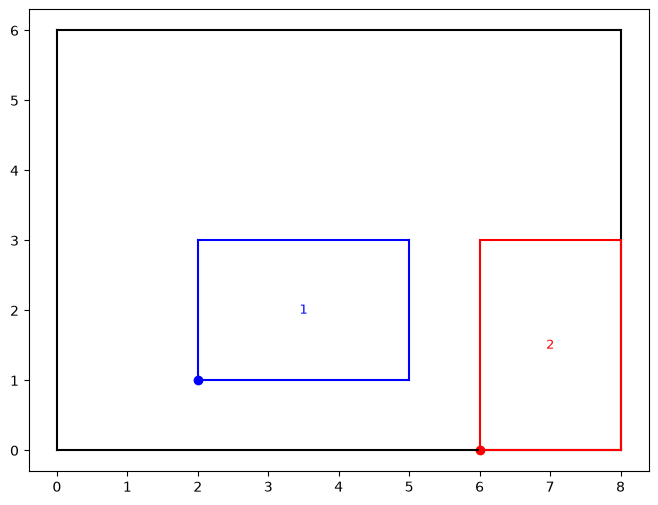

In [17]:
def plotar_caixa(bottom_left: list,
                 l: int,
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0 + l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0 + w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l], [y0, y0 + w], color=color)
    plt.text(x=x0 + l/2, y=y0 + w/2, s=label, color=color,
             fontsize=9, ha="center", va="center")

def plotar_palete(L: int, W: int):
    plt.figure(figsize=(8, 6))
    plt.plot([0, L], [0, 0], "k-")
    plt.plot([0, 0], [0, W], "k-")
    plt.plot([0, L], [W, W], "k-")
    plt.plot([L, L], [0, W], "k-")
plotar_palete(L, W)
plotar_caixa(bottom_left=[2, 1], l=3, w=2, color="blue", label="1")
plotar_caixa(bottom_left=[6, 0], l=2, w=3, color="red", label="2")

In [18]:
f_um = lambda n_um, l_um, n_dois, l_dois: \
    n_um * l_um + n_dois * l_dois

f_dois = lambda n_um, w_um, n_dois, w_dois: \
    n_um * w_um + n_dois * w_dois

In [ ]:
print(f_um(n_um=2, l_um=3, n_dois=1, l_dois=2))                  # p <= L - w_um
print(f_dois(n_um=2, w_um=2, n_dois=1, w_dois=3))                # q <= W - w_um

8
7


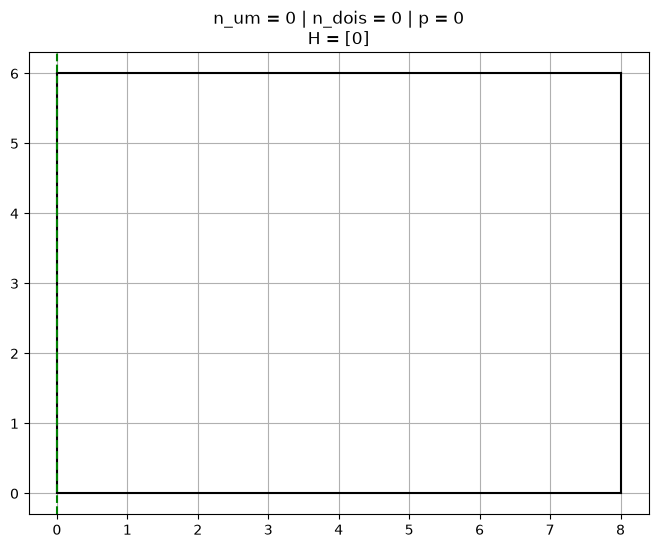

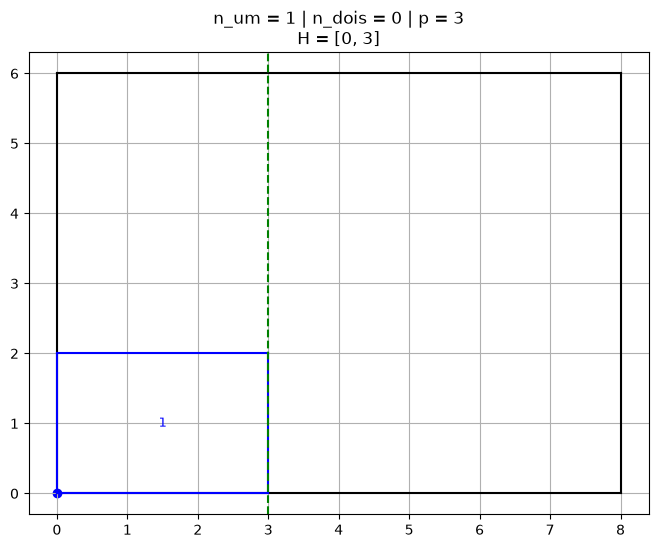

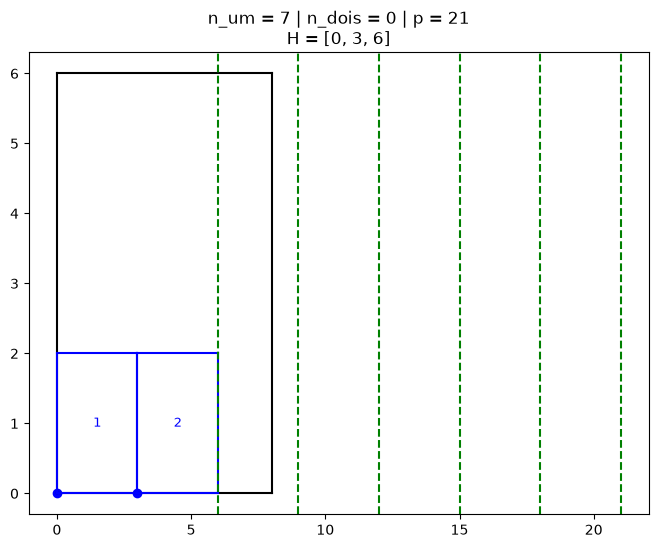

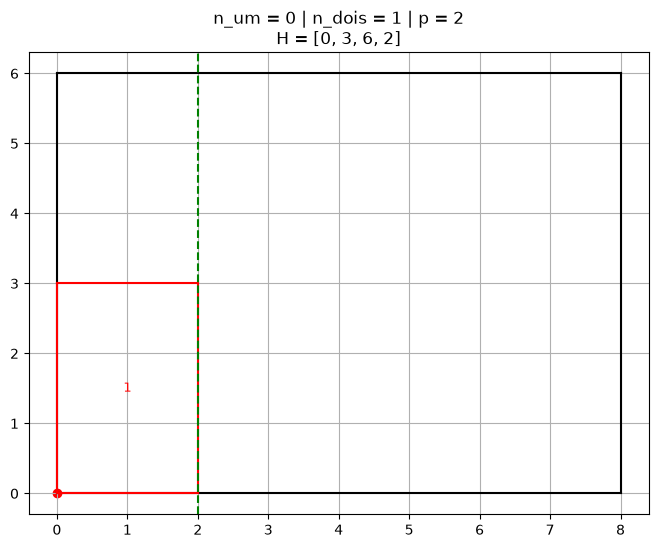

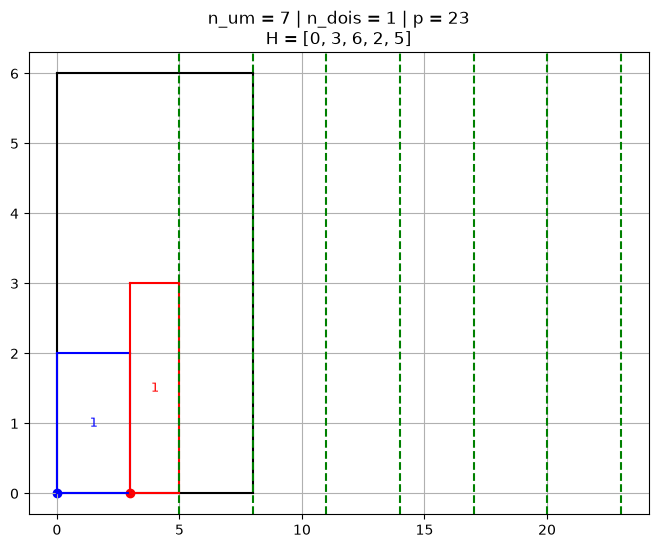

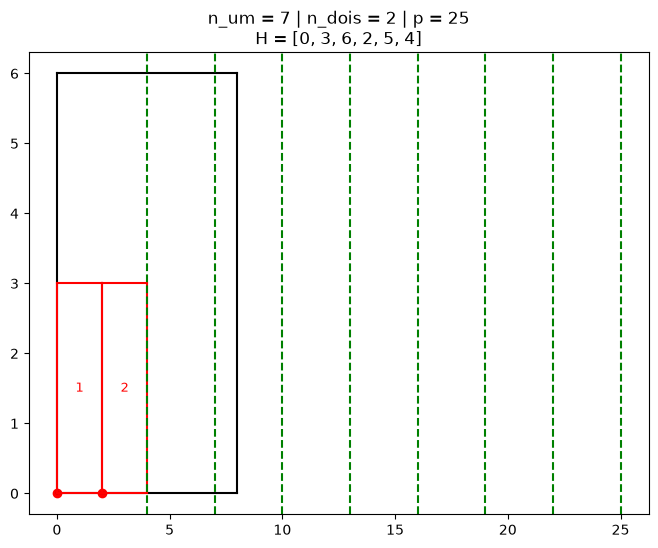

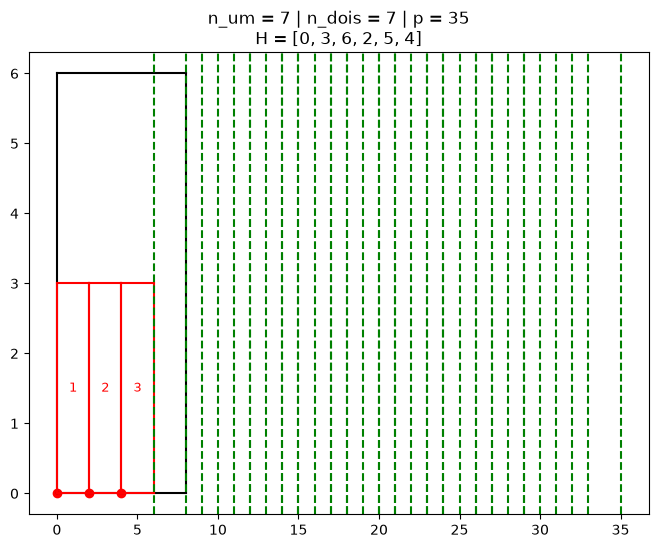

In [28]:
H = []
for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)
    # print(n_um, n_dois, p)
    if p <= L - w_um:

        if p not in H:
            H.append(p)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[n * l_um, 0], l=l_um, w=w_um,
                        color="blue", label=n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[n_um * l_um + n * l_dois, 0],
                         l=l_dois, w=w_dois, color="red",
                         label=n+1)

    plt.axvline(x=p, color="green", linestyle="--")
    plt.title(f"{n_um = } | {n_dois = } | {p = }\n{H = }")
    plt.grid()

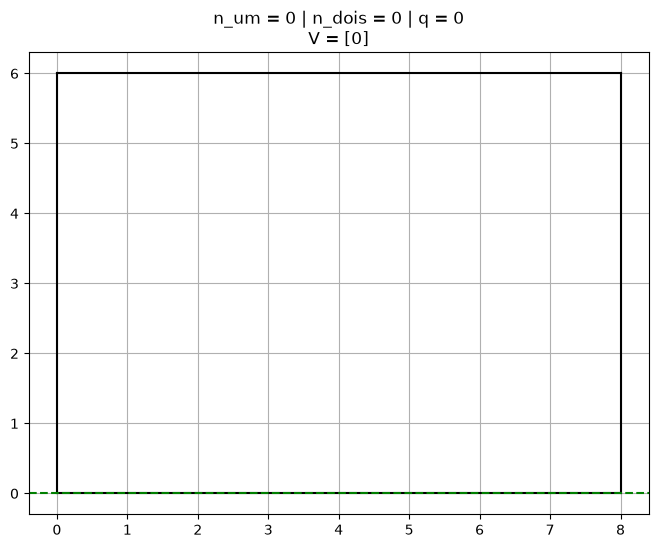

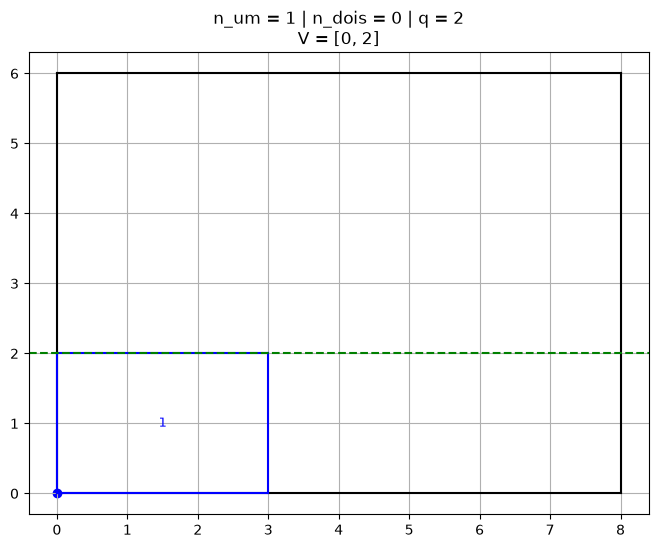

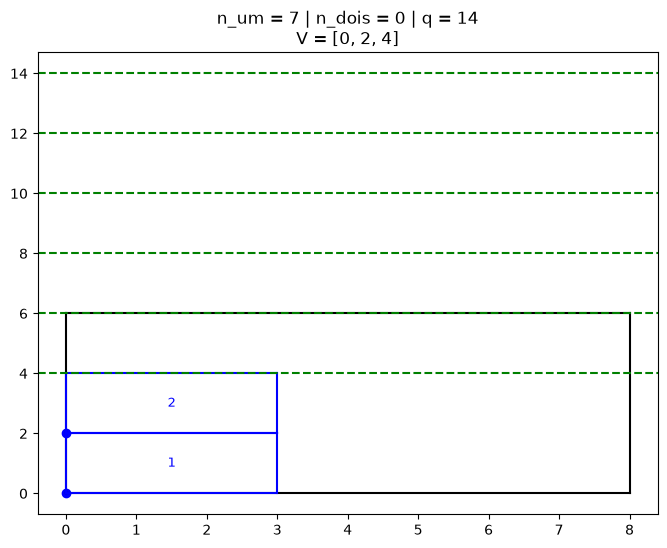

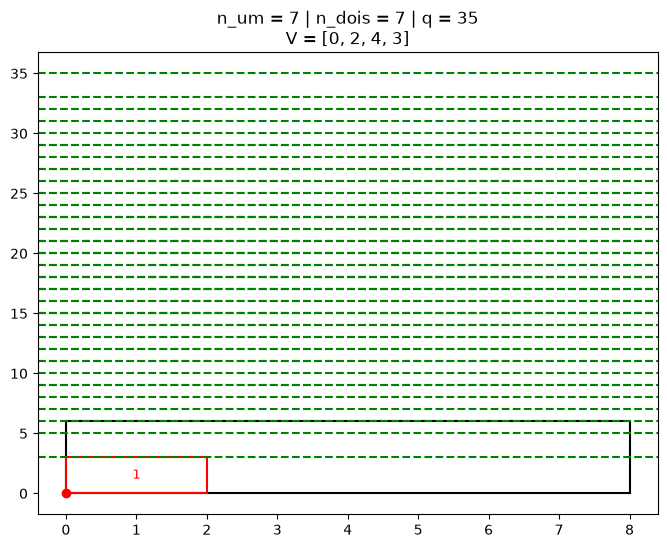

In [30]:
V = []
for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    # print(n_um, n_dois, q)
    if q <= W - w_um:

        if q not in V:
            V.append(q)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[0,n * w_um], l=l_um, w=w_um,
                        color="blue", label=n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[0, n_um * w_um + n * w_dois],
                         l=l_dois, w=w_dois, color="red",
                         label=n+1)

    plt.axhline(y=q, color="green", linestyle="--")
    plt.title(f"{n_um = } | {n_dois = } | {q = }\n{V = }")
    plt.grid()

In [31]:
H = sorted(H)
V = sorted(V)
print(H)
print(V)

[0, 2, 3, 4, 5, 6]
[0, 2, 3, 4]
